EDA – Steam Games Dataset (2021–2025)

In [1]:
pip install pandas numpy matplotlib seaborn ydata-profiling

Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,

## 1. Automated EDA Report (ydata-profiling)

In [3]:
import pandas as pd
from ydata_profiling import ProfileReport

df = pd.read_csv("a_steam_data_2021_2025.csv")

print("First 5 rows:")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

profile = ProfileReport(df, title="Steam Games EDA Report", explorative=True)
profile.to_file("Steam_EDA_Report.html")
print("\nEDA Report generated successfully!")

ModuleNotFoundError: No module named 'ydata_profiling'

## 2. Manual EDA (Pandas, Matplotlib, Seaborn)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("a_steam_data_2021_2025.csv")
print("DATASET LOADED SUCCESSFULLY")

DATASET LOADED SUCCESSFULLY


### Basic understanding

In [4]:
print("First 5 Records:");  print(df.head())
print("\nLast 5 Records:");  print(df.tail())
print("\nRandom 5 Records:"); print(df.sample(5, random_state=1))
print("\nShape:", df.shape)
print("Columns:", df.columns.tolist())
df.info()
print(df.dtypes)

First 5 Records:
     appid                        name  release_year  release_date  \
0  3057270           Seafarer's Gambit          2024   Jul 5, 2024   
1  3822840    Capitalist Misadventures          2025  Jul 25, 2025   
2  3216640  The Beast and the Princess          2025  Jun 17, 2025   
3  2403620                 Air Twister          2023  Nov 10, 2023   
4  1538040                Horde Slayer          2021  Mar 19, 2021   

                                           genres  \
0             Action;Adventure;Indie;RPG;Strategy   
1                Casual;Indie;Simulation;Strategy   
2                        Adventure;Indie;Strategy   
3                          Action;Adventure;Indie   
4  Action;Adventure;Casual;Indie;RPG;Early Access   

                                          categories  price  recommendations  \
0                       Single-player;Family Sharing   3.99                0   
1          Single-player;Save Anytime;Family Sharing   7.99                0   
2  

### Statistical summary

In [5]:
print(df.describe())
print(df.describe(include="all"))
numerical_columns = df.select_dtypes(include=np.number).columns.drop("appid")
categorical_columns = df.select_dtypes(exclude=np.number).columns
print("Numerical:", list(numerical_columns))
print("Categorical:", list(categorical_columns))

              appid  release_year         price  recommendations
count  6.552100e+04  65521.000000  65521.000000     65521.000000
mean   2.580607e+06   2023.453091      7.204043       362.165336
std    7.692480e+05      1.386641     16.914429      6936.837198
min    1.200220e+06   2021.000000      0.000000         0.000000
25%    1.916970e+06   2022.000000      0.990000         0.000000
50%    2.516050e+06   2024.000000      3.990000         0.000000
75%    3.193800e+06   2025.000000      9.740000         0.000000
max    4.243930e+06   2025.000000   1900.000000    862487.000000
               appid           name  release_year release_date        genres  \
count   6.552100e+04          65521  65521.000000        65521         65455   
unique           NaN          65128           NaN         1828          1723   
top              NaN  Zombie Hunter           NaN         2025  Casual;Indie   
freq             NaN              5           NaN          836          4136   
mean    2.58060

### Missing values and duplicates

In [6]:
missing = df.isnull().sum()
missing_pct = missing / len(df) * 100
print(pd.DataFrame({"missing": missing, "percent": missing_pct.round(3)})[missing > 0])

# Text columns -> fill with "Unknown"
for col in ["genres", "categories", "developer", "publisher"]:
    df[col] = df[col].fillna("Unknown")

print("\nMissing after treatment:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate appid:", df["appid"].duplicated().sum())
df = df.drop_duplicates()
print("Shape:", df.shape)

            missing  percent
genres           66    0.101
categories        7    0.011
developer        53    0.081
publisher       183    0.279

Missing after treatment: 0
Duplicate rows: 0
Duplicate appid: 0
Shape: (65521, 10)


### Data cleaning / feature engineering

In [7]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["release_month"] = df["release_date"].dt.month
df["is_free"] = df["price"] == 0
df["has_recommendations"] = df["recommendations"] > 0
df["genre_count"] = df["genres"].str.split(";").str.len()
print(df[["release_date", "is_free", "genre_count"]].head())
print("Unparsed dates:", df["release_date"].isnull().sum())

  release_date  is_free  genre_count
0   2024-07-05    False            5
1   2025-07-25    False            4
2   2025-06-17    False            3
3   2023-11-10    False            3
4   2021-03-19    False            6
Unparsed dates: 1400


### Unique values and value counts

In [8]:
for col in df.columns:
    print(col, "->", df[col].nunique())

for col in ["developer", "publisher"]:
    print("\nTop 10", col)
    print(df[col].value_counts().head(10))

appid -> 65521
name -> 65128
release_year -> 5
release_date -> 1825
genres -> 1724
categories -> 7994
price -> 589
recommendations -> 2536
developer -> 45680
publisher -> 41601
release_month -> 12
is_free -> 2
has_recommendations -> 2
genre_count -> 11

Top 10 developer
developer
EroticGamesClub          215
Bully Revenge Studios    119
Gamesforgames             96
Do Games Limited          90
Archor Wright             88
King Kong                 87
Boogygames Studios        84
Cyber Keks                83
Cute Hannah's Games       72
Follow the fun            72
Name: count, dtype: int64

Top 10 publisher
publisher
EroticGamesClub                    215
Unknown                            183
BFG Entertainment                  172
8floor                             150
Hede                               142
Kagura Games                       120
Bully Revenge Studios              119
DigiPen Institute of Technology    100
Gamesforgames                       98
indie.io                

### Genres, categories and release year

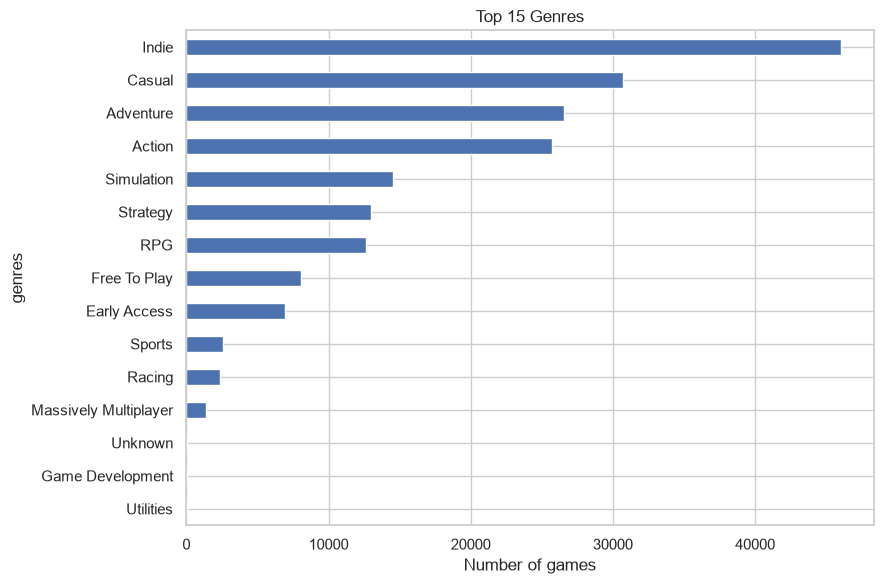

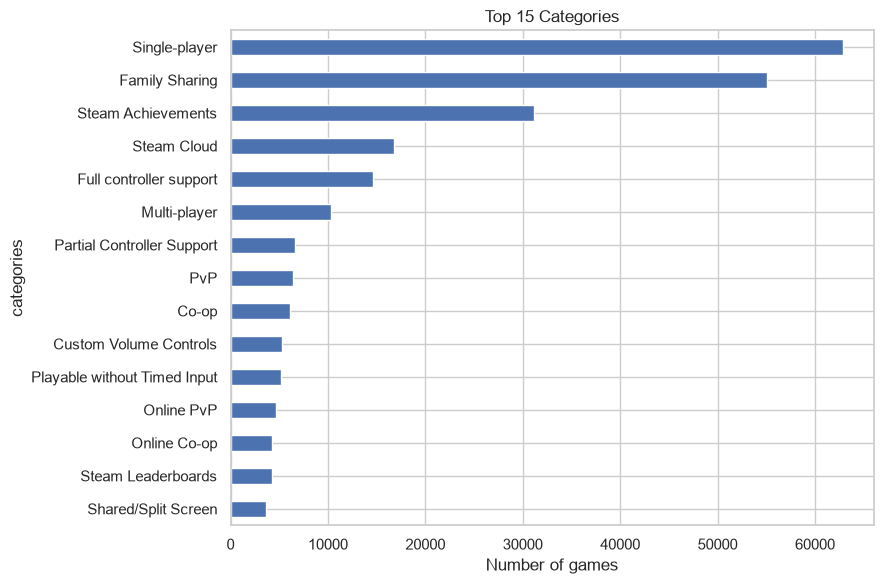

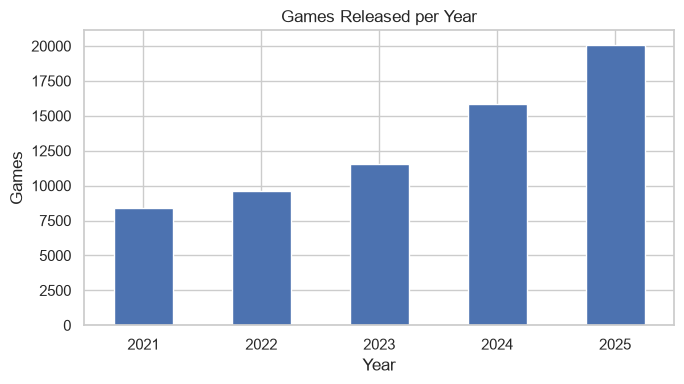

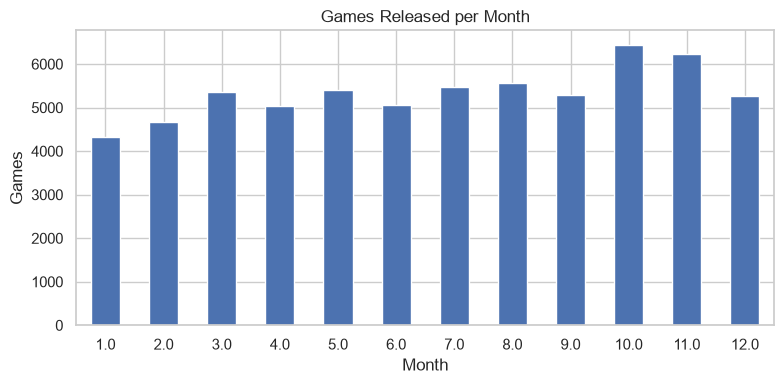

In [9]:
# Genres / categories are ';' separated -> explode into one row per value
genres = df["genres"].str.split(";").explode()
categories = df["categories"].str.split(";").explode()

plt.figure(figsize=(9, 6))
genres.value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Genres"); plt.xlabel("Number of games")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 6))
categories.value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Categories"); plt.xlabel("Number of games")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
df["release_year"].value_counts().sort_index().plot(kind="bar")
plt.title("Games Released per Year"); plt.xlabel("Year"); plt.ylabel("Games")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
df["release_month"].value_counts().sort_index().plot(kind="bar")
plt.title("Games Released per Month"); plt.xlabel("Month"); plt.ylabel("Games")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Price analysis

Free games: 18.3%
count    65521.000000
mean         7.204043
std         16.914429
min          0.000000
25%          0.990000
50%          3.990000
75%          9.740000
max       1900.000000
Name: price, dtype: float64


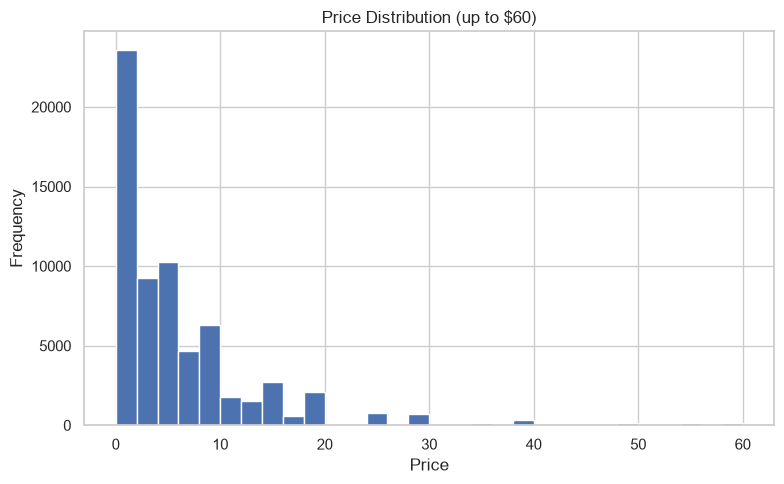

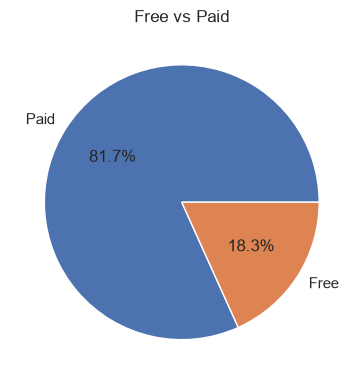


Average price per year:
release_year
2021    6.62
2022    7.14
2023    7.68
2024    7.58
2025    6.91
Name: price, dtype: float64

Average price of paid games by top genre:
genre
Sports          18.79
RPG             12.00
Simulation      11.43
Strategy        10.94
Adventure       10.00
Action           9.78
Early Access     9.55
Indie            7.93
Casual           7.75
Free To Play     6.73
Name: price, dtype: float64


In [10]:
print("Free games: %.1f%%" % (df["is_free"].mean() * 100))
print(df["price"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df.loc[df["price"] <= 60, "price"], bins=30)
plt.title("Price Distribution (up to $60)"); plt.xlabel("Price"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
df["is_free"].map({True: "Free", False: "Paid"}).value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Free vs Paid"); plt.ylabel("")
plt.tight_layout(); plt.show()

print("\nAverage price per year:")
print(df.groupby("release_year")["price"].mean().round(2))
print("\nAverage price of paid games by top genre:")
top_genres = genres.value_counts().head(10).index
g = df.assign(genre=df["genres"].str.split(";")).explode("genre")
print(g[g["genre"].isin(top_genres) & ~g["is_free"]].groupby("genre")["price"].mean().sort_values(ascending=False).round(2))

### Recommendations (popularity)

Games with at least 1 recommendation: 12.2%
count     65521.000000
mean        362.165336
std        6936.837198
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      862487.000000
Name: recommendations, dtype: float64


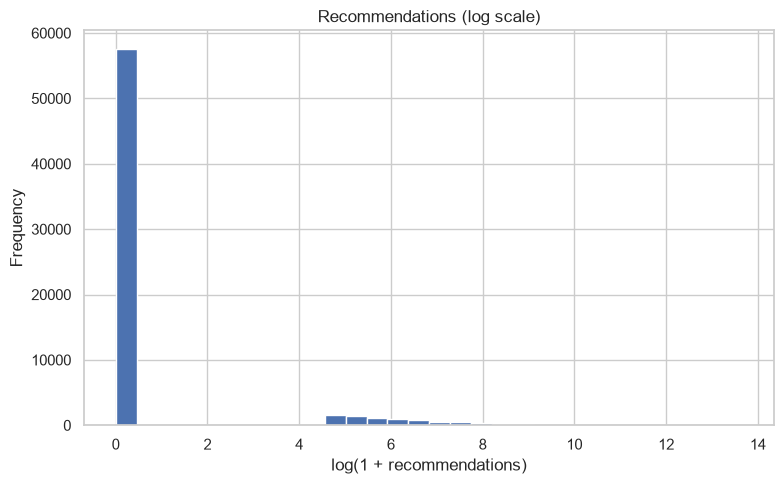


Top 10 most recommended games:
                     name  release_year  price  recommendations
15892  Black Myth: Wukong          2024  59.99           862487
12832          ELDEN RING          2022  59.99           793463
47520       Call of Duty®          2022   0.00           402294
36937      Lethal Company          2023   9.99           401836
36391            Palworld          2024  22.49           342592
22559            R.E.P.O.          2025   9.99           265041
6105    Battlefield™ 2042          2021  59.99           256797
53405  Sons Of The Forest          2024  29.99           249253
24424   Vampire Survivors          2022   4.99           244333
21173          Schedule I          2025  19.99           239325


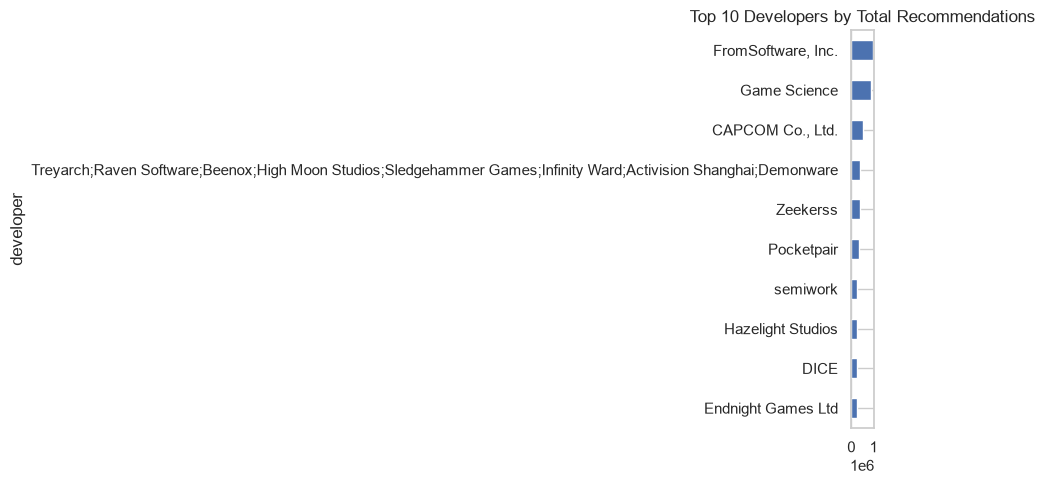


Mean recommendations by year:
release_year
2021    418.3
2022    481.6
2023    375.6
2024    381.8
2025    258.4
Name: recommendations, dtype: float64


In [11]:
print("Games with at least 1 recommendation: %.1f%%" % (df["has_recommendations"].mean() * 100))
print(df["recommendations"].describe())

plt.figure(figsize=(8, 5))
plt.hist(np.log1p(df["recommendations"]), bins=30)
plt.title("Recommendations (log scale)"); plt.xlabel("log(1 + recommendations)"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()

print("\nTop 10 most recommended games:")
print(df.nlargest(10, "recommendations")[["name", "release_year", "price", "recommendations"]])

top = df.groupby("developer")["recommendations"].sum().drop("Unknown", errors="ignore").nlargest(10)
plt.figure(figsize=(9, 5))
top.sort_values().plot(kind="barh")
plt.title("Top 10 Developers by Total Recommendations")
plt.tight_layout(); plt.show()

print("\nMean recommendations by year:")
print(df.groupby("release_year")["recommendations"].mean().round(1))

### Distributions and outliers

C:\Users\DELL\AppData\Local\Temp\ipykernel_5388\912703492.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


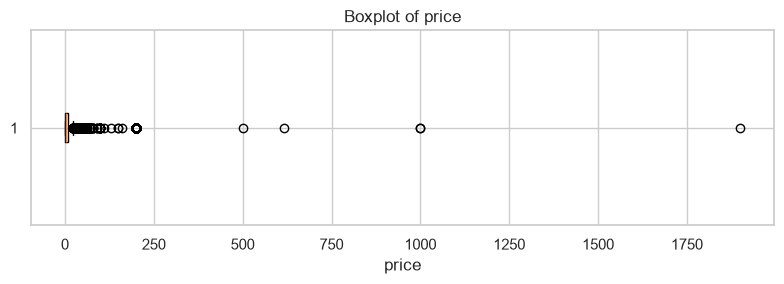

C:\Users\DELL\AppData\Local\Temp\ipykernel_5388\912703492.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


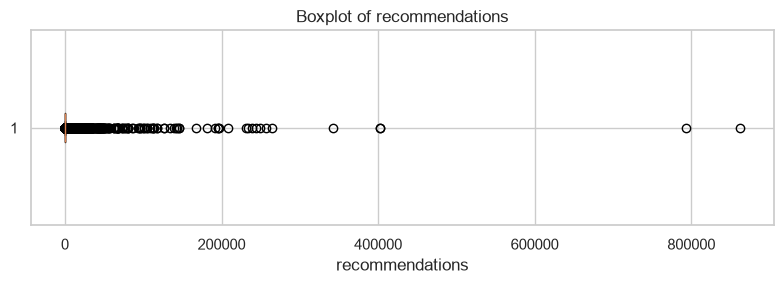

C:\Users\DELL\AppData\Local\Temp\ipykernel_5388\912703492.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


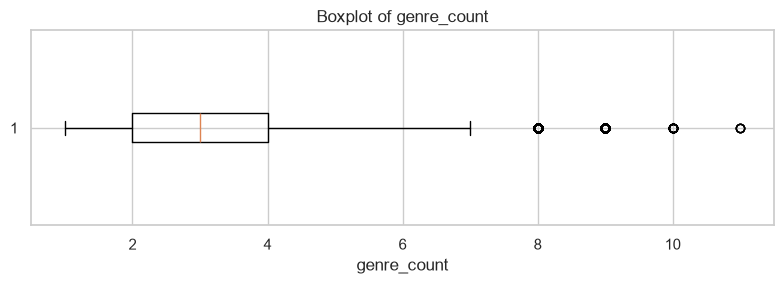

OUTLIER ANALYSIS (IQR)
price: Q1=0.99, Q3=9.74, IQR=8.75, lower=-12.135, upper=22.865000000000002, outliers=2779
recommendations: Q1=0.0, Q3=0.0, IQR=0.0, lower=0.0, upper=0.0, outliers=8006
genre_count: Q1=2.0, Q3=4.0, IQR=2.0, lower=-1.0, upper=7.0, outliers=346


In [12]:
cols = ["price", "recommendations", "genre_count"]
for col in cols:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title("Boxplot of " + col); plt.xlabel(col)
    plt.tight_layout(); plt.show()

print("OUTLIER ANALYSIS (IQR)")
for col in cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: Q1={Q1}, Q3={Q3}, IQR={IQR}, lower={lo}, upper={hi}, outliers={n}")

### Correlation

                 release_year     price  recommendations  genre_count
release_year         1.000000  0.009118        -0.034027     0.033329
price                0.009118  1.000000         0.321698    -0.097322
recommendations     -0.034027  0.321698         1.000000     0.010180
genre_count          0.033329 -0.097322         0.010180     1.000000


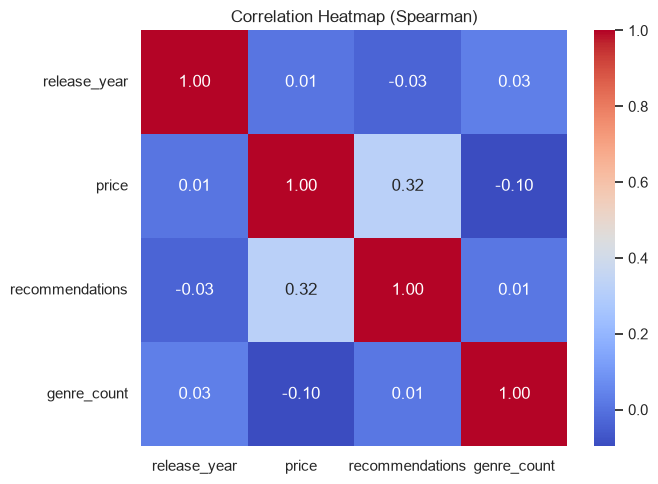

In [14]:
num = df[["release_year", "price", "recommendations", "genre_count"]]
correlation = num.corr(method="spearman")   # spearman: price/recommendations are heavily skewed
print(correlation)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Spearman)")
plt.tight_layout(); plt.show()

### Key findings

- Add your own observations here after running the cells (growth of releases per year, share of free games, most common genres, how skewed recommendations are).